# Poster NeRF

Train a small NeRF on the poster data using PyTorch3D.

In [1]:
from pathlib import Path  
import json  


import cv2   
import numpy as np 
import matplotlib.pyplot as plt
from PIL import Image



import torch    
from pytorch3d.renderer import (
    PerspectiveCameras,
    MonteCarloRaysampler,
    NDCMultinomialRaysampler,
    EmissionAbsorptionRaymarcher,
    RayBundle,
    ray_bundle_to_ray_points,
)



device = torch.device("cuda")   
print(torch.cuda.get_device_name(0))  

NVIDIA GeForce RTX 3060


## Data

The dataset has four image folders that has the same 226 views at different sizes. I managed to run it using the highest resolution data using my 12GB VRAM nvidia gpu on Ubuntu. So, this final run uses the full-resolution "images" folder (1080 × 1920).

In [2]:
data_dir = Path("data/poster")   
image_folder = "images"   
  
  
output_dir = Path("poster_outputs")   
output_dir.mkdir(exist_ok=True)   
  
 

with (data_dir / "transforms.json").open() as file:   
    transforms = json.load(file)   
   
frames = sorted(transforms["frames"], key=lambda frame: frame["file_path"])   
frame_ids = [Path(frame["file_path"]).name for frame in frames]   
   

print("Images:", len(frames))  

   
for folder in ["images", "images_2", "images_4", "images_8"]:    
    with Image.open(data_dir / folder / frame_ids[0]) as image:    
        print(folder, image.size) 

Images: 226
images (1080, 1920)
images_2 (540, 960)
images_4 (270, 480)
images_8 (135, 240)


The code below uses the slightly adjusted version of the load_nerf_data.py code that was in the dataset folder. It uses the poster camera settings. The saved poses already include "applied_transform", so it is not applied again. The images are kept in one CPU tensor.




In [3]:
def load_nerf_data(data_dir, image_folder):   
    with open(data_dir / "transforms.json") as f:   
        transforms_data = json.load(f)  

     
    frames = sorted(transforms_data["frames"], key=lambda frame: frame["file_path"])   
    
    first_image = data_dir / image_folder / Path(frames[0]["file_path"]).name  
    with Image.open(first_image) as img:   
        width, height = img.size  
     
  
    # Keep one copy of the images in RAM   
    target_images = torch.empty(   
        (len(frames), height, width, 3),
        dtype=torch.float32,   
    )   
   
  
   
    Rs, Ts = [], []    
    axis_change = torch.diag(torch.tensor([-1.0, 1.0, -1.0]))   
     
  
    for index, frame in enumerate(frames):
        img_path = data_dir / image_folder / Path(frame["file_path"]).name    
     
        with Image.open(img_path) as img:    
            img_np = np.array(img).astype(np.float32) / 255.0    
   
        target_images[index] = torch.from_numpy(img_np)   
   
    
        c2w = torch.tensor(frame["transform_matrix"], dtype=torch.float32)   
        R_nerf = c2w[:3, :3]  
        T_nerf = c2w[:3, 3]   

        # Convert the saved camera axes to PyTorch3D    
        R_pytorch3d = R_nerf @ axis_change   
        T_pytorch3d = -T_nerf @ R_pytorch3d  
        Rs.append(R_pytorch3d)  
        Ts.append(T_pytorch3d)  



    scale_x = width / transforms_data["w"]   
    scale_y = height / transforms_data["h"]   

 
    target_cameras = PerspectiveCameras( 
        R=torch.stack(Rs),    
        T=torch.stack(Ts),   
        focal_length=((    
            transforms_data["fl_x"] * scale_x,  
            transforms_data["fl_y"] * scale_y, 
        ),),
        principal_point=((
            transforms_data["cx"] * scale_x,
            transforms_data["cy"] * scale_y,
        ),),
        image_size=((height, width),),
        in_ndc=False,
    )
   
    return target_images, target_cameras   

Train: 203 Test: 23


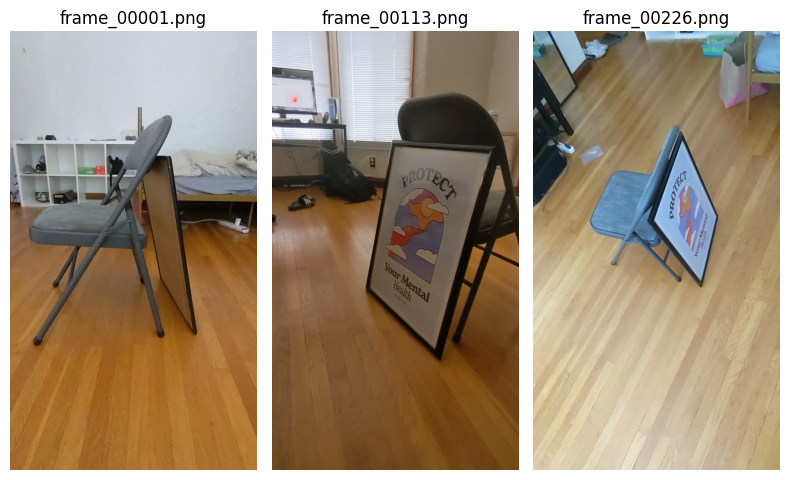

In [4]:
target_images, target_cameras = load_nerf_data(data_dir, image_folder)   
image_height, image_width = target_images.shape[1:3]  
     


# Every tenth image is kept for testing    
indices = torch.arange(len(frames)) 
test_indices = indices[indices % 10 == 1]  
train_indices = indices[indices % 10 != 1]  

print("Train:", len(train_indices), "Test:", len(test_indices))   
  

   

fig, axes = plt.subplots(1, 3, figsize=(8, 5))   

for ax, index in zip(axes, [0, 112, 225]):  
    ax.imshow(target_images[index])   
    ax.set_title(frame_ids[index])
    ax.axis("off")  
   

plt.tight_layout()   
plt.show()   

## Model   

I have mostly used the official documentation of NeRF, and some of the pages I have used is linked below.    

The position network has two hidden layers with 256 units. The colour branch also takes the viewing direction and has one extra hidden layer.      
    
   
Positions use 10 frequency bands and directions use 4. The original coordinates are included: https://github.com/bmild/nerf/blob/master/run_nerf_helpers.py   

   
Density and the distance between samples give the opacity used for rendering: https://github.com/bmild/nerf/blob/master/run_nerf.py   


In [5]:
class HarmonicEmbedding(torch.nn.Module):    

    def __init__(self, n_harmonic_functions):    

        super().__init__()   
        self.register_buffer(  
            'frequencies',   
            2.0 ** torch.arange(n_harmonic_functions),   
        )  


    def forward(self, x):   
        embed = (x[..., None] * self.frequencies).view(*x.shape[:-1], -1)  
        return torch.cat((x, embed.sin(), embed.cos()), dim=-1)   
  
     


class NeuralRadianceField(torch.nn.Module):  
    def __init__(self, n_hidden_neurons=256):    
        super().__init__()    
   
        self.position_embedding = HarmonicEmbedding(10)   
        self.direction_embedding = HarmonicEmbedding(4)   
  
        position_dim = 3 + 10 * 2 * 3  
        direction_dim = 3 + 4 * 2 * 3
  

        self.mlp = torch.nn.Sequential(    
            torch.nn.Linear(position_dim, n_hidden_neurons),
            torch.nn.Softplus(beta=10.0),
            torch.nn.Linear(n_hidden_neurons, n_hidden_neurons),   
            torch.nn.Softplus(beta=10.0),
        )



        self.color_layer = torch.nn.Sequential(      
            torch.nn.Linear(n_hidden_neurons + direction_dim, n_hidden_neurons),
            torch.nn.Softplus(beta=10.0),
            torch.nn.Linear(n_hidden_neurons, 3),
            torch.nn.Sigmoid(),

        )  


        self.density_layer = torch.nn.Sequential(    
            torch.nn.Linear(n_hidden_neurons, 1),  
            torch.nn.Softplus(beta=10.0),   

        )

        self.density_layer[0].bias.data[0] = -1.5    

    def _get_densities(self, features, ray_bundle):   
        raw_densities = self.density_layer(features)    

   
        depths = ray_bundle.lengths  
        intervals = depths[..., 1:] - depths[..., :-1]  
        last_interval = max_depth - depths[..., -1:]   
        intervals = torch.cat((intervals, last_interval), dim=-1)   

        # Depth is measured along camera z, include the ray direction length   
        distances = intervals * ray_bundle.directions.norm(dim=-1, keepdim=True)

        return 1 - (-raw_densities * distances[..., None]).exp()    

    def _get_colors(self, features, rays_directions):   
        spatial_size = features.shape[:-1]  
  
        rays_directions_normed = torch.nn.functional.normalize( 
            rays_directions, dim=-1   
        )  

        rays_embedding = self.direction_embedding(  
            rays_directions_normed  
        )

        rays_embedding_expand = rays_embedding[..., None, :].expand(  
            *spatial_size, rays_embedding.shape[-1]   
        )

        color_layer_input = torch.cat(
            (features, rays_embedding_expand),     
            dim=-1
        )
        return self.color_layer(color_layer_input)   



    def forward(self, ray_bundle):   

        rays_points_world = ray_bundle_to_ray_points(ray_bundle)  

        embeds = self.position_embedding( 
            rays_points_world
        )

        features = self.mlp(embeds)

 
        rays_densities = self._get_densities(features, ray_bundle)  

        rays_colors = self._get_colors(features, ray_bundle.directions)  

        return rays_densities, rays_colors   

## Training   

Train for 20,000 updates. Each update uses three images, 750 rays per image and 256 samples per ray. Adam starts at 0.001. Its learning rate changes to 0.0001 after 15,000 updates.   

Sample depths from 0.01 to 32.0. Training uses random depths and RGB MSE loss. Rendering uses fixed depths: This: https://docs.opencv.org/4.13.0/d9/d0c/group__calib3d.html is for correcting the ray directions for lens distortion, the target photos stay unchanged.  

In [6]:
n_iter = 20000    
batch_size = 3    
lr = 1e-3    


samples_per_ray = 256    
min_depth = 0.01   
max_depth = 32.0  



range_x = image_width / min(image_height, image_width)    
range_y = image_height / min(image_height, image_width)   


raysampler_mc = MonteCarloRaysampler(     
    min_x=-range_x + range_x / image_width,   
    max_x=range_x - range_x / image_width,  
    min_y=-range_y + range_y / image_height,
    max_y=range_y - range_y / image_height,  
    n_rays_per_image=750,   
    n_pts_per_ray=samples_per_ray,  
    min_depth=min_depth,   
    max_depth=max_depth,  
    stratified_sampling=True, 
).to(device)     
 
raymarcher = EmissionAbsorptionRaymarcher()   



scale_x = image_width / transforms["w"]   
scale_y = image_height / transforms["h"]   

camera_matrix = np.array([   
    [transforms["fl_x"] * scale_x, 0, transforms["cx"] * scale_x],   
    [0, transforms["fl_y"] * scale_y, transforms["cy"] * scale_y], 
    [0, 0, 1],
])


distortion_coefficients = np.array([   
    transforms["k1"], transforms["k2"],    
    transforms["p1"], transforms["p2"],    
])









def correct_ray_directions(rays, cameras):    
    pixels = rays.xys.detach().cpu().numpy().reshape(-1, 2).copy()   
    ndc_scale = min(image_height, image_width) / 2
    pixels[:, 0] = image_width / 2 - pixels[:, 0] * ndc_scale   
    pixels[:, 1] = image_height / 2 - pixels[:, 1] * ndc_scale


    ideal = cv2.undistortPoints(    

        pixels[:, None, :],    
        camera_matrix,
        distortion_coefficients,
    )[:, 0, :]


    camera_directions = np.column_stack((-ideal, np.ones(len(ideal))))   
    camera_directions = camera_directions.astype(np.float32)  
    camera_directions = torch.from_numpy(camera_directions).to(device)      
    camera_directions = camera_directions.reshape(len(cameras), -1, 3)   

    world_directions = torch.bmm(camera_directions, cameras.R.transpose(1, 2))   



    # Keep the original pixel coordinates for the target colours    
    return RayBundle(
        origins=rays.origins,
        directions=world_directions.reshape_as(rays.directions),
        lengths=rays.lengths,
        xys=rays.xys,
    )








def sample_rgb(target_images, sampled_rays_xy):     
    num_images = target_images.shape[0] 
    num_channels = target_images.shape[-1]   
    spatial_size = sampled_rays_xy.shape[1:-1]  
   
    
    height, width = target_images.shape[1:3]
    ranges = target_images.new_tensor([    
        width / min(height, width),
        height / min(height, width),   
    ])


   
    # Scale rectangular image coordinates to [-1, 1] for grid_sample    
    sampled_rays_xy = sampled_rays_xy / ranges   

    images_sampled = torch.nn.functional.grid_sample(   
        target_images.permute(0, 3, 1, 2),    
        -sampled_rays_xy.view(num_images, -1, 1, 2),    
        align_corners=False   
    )
    return images_sampled.permute(0, 2, 3, 1).view(   
        num_images, *spatial_size, num_channels   
    )

In [7]:
torch.manual_seed(1)    
model = NeuralRadianceField()   
model = model.to(device)   



    
optimizer = torch.optim.Adam(    
    model.parameters(),   
    lr=lr,
)
loss_history = []







for iteration in range(n_iter):  
    if iteration == round(n_iter * 0.75):   
        for group in optimizer.param_groups:   
            group["lr"] = lr * 0.1   


    optimizer.zero_grad()   
    random_order = torch.randperm(len(train_indices))   
    batch_idx = train_indices[random_order[:batch_size]]  
    batch_cameras = target_cameras[batch_idx].to(device)   

    sampled_rays = raysampler_mc(cameras=batch_cameras)    
    sampled_rays = correct_ray_directions(sampled_rays, batch_cameras)  
    

    opacity, colour = model(sampled_rays)     
    rendered = raymarcher(rays_densities=opacity, rays_features=colour)      
    rendered_images = rendered[..., :3]   
       
    colors_at_rays = sample_rgb(   
        target_images[batch_idx].to(device),  
        sampled_rays.xys,  
    )   
   
    loss = torch.nn.functional.mse_loss(rendered_images, colors_at_rays)   
    loss_history.append(float(loss))  



    loss.backward()  
    optimizer.step()  


    if (iteration + 1) % 100 == 0:   
        print(iteration + 1, round(float(loss), 5))




    


torch.save(model.state_dict(), output_dir / "model.pt")     

np.savez_compressed(output_dir / "loss_history.npz", total=loss_history)   

100 0.02691
200 0.02822
300 0.02156
400 0.01603
500 0.01512
600 0.01792
700 0.01445
800 0.01649
900 0.00923
1000 0.01719
1100 0.01305
1200 0.01142
1300 0.01626
1400 0.01462
1500 0.01592
1600 0.00951
1700 0.01061
1800 0.01023
1900 0.01062
2000 0.00902
2100 0.01178
2200 0.00935
2300 0.00977
2400 0.00832
2500 0.01147
2600 0.01049
2700 0.00848
2800 0.00869
2900 0.00909
3000 0.0063
3100 0.0086
3200 0.00722
3300 0.00774
3400 0.00856
3500 0.00904
3600 0.00617
3700 0.00754
3800 0.0074
3900 0.00754
4000 0.00574
4100 0.00541
4200 0.00927
4300 0.00607
4400 0.00875
4500 0.00648
4600 0.00634
4700 0.00544
4800 0.00648
4900 0.00573
5000 0.00533
5100 0.00462
5200 0.00585
5300 0.00632
5400 0.00622
5500 0.00528
5600 0.00583
5700 0.00615
5800 0.00472
5900 0.00688
6000 0.00524
6100 0.00692
6200 0.00536
6300 0.00519
6400 0.005
6500 0.00531
6600 0.00432
6700 0.00538
6800 0.00571
6900 0.00537
7000 0.00537
7100 0.00484
7200 0.00538
7300 0.0057
7400 0.00549
7500 0.00384
7600 0.0039
7700 0.00516
7800 0.00409
79

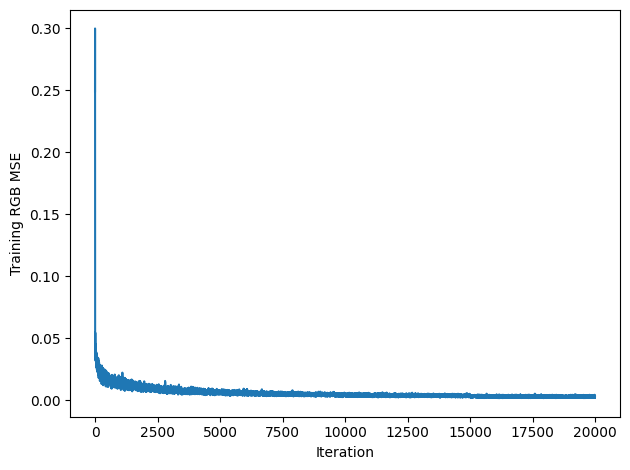

In [8]:
plt.plot(range(1, n_iter + 1), loss_history)     



plt.xlabel("Iteration")   
plt.ylabel("Training RGB MSE")  




plt.tight_layout()   
plt.savefig(output_dir / "loss.png", dpi=150)   
plt.show()    

## Test images

Rendering the 23 test views, 1,024 rays at a time. Saving the predicted images, target photos and filenames in "poster_test_images.npz" for evaluation.   

In [9]:
raysampler_grid = NDCMultinomialRaysampler(   
    image_height=image_height,   
    image_width=image_width,
    n_pts_per_ray=samples_per_ray,
    min_depth=min_depth,   
    max_depth=max_depth,
    stratified_sampling=False,  
).to(device)  
   




  

  

def render_image(camera):   
    with torch.no_grad():  
        rays = raysampler_grid(cameras=camera)
        rays = correct_ray_directions(rays, camera)  
  
    
        origins = rays.origins.reshape(-1, 3)   
        directions = rays.directions.reshape(-1, 3)  
        lengths = rays.lengths.reshape(-1, samples_per_ray)  
        xy = rays.xys.reshape(-1, 2)    

  
        image = torch.empty((image_height * image_width, 3))   



    
        for start in range(0, len(image), 1024):
            stop = start + 1024      
            chunk = RayBundle(
                origins=origins[None, start:stop],
                directions=directions[None, start:stop],  
                lengths=lengths[None, start:stop],   
                xys=xy[None, start:stop], 
                     
            )


            opacity, colour = model(chunk)   
            rendered = raymarcher(rays_densities=opacity, rays_features=colour)  
            image[start:stop] = rendered[0, :, :3].cpu()  



    return image.reshape(image_height, image_width, 3).clamp(0, 1)    

In [10]:
model.eval()  

   
  

predictions = []  
test_names = [frame_ids[index] for index in test_indices.tolist()]   
  


  

  
for index in test_indices.tolist():  
    image = render_image(target_cameras[index].to(device))  
    predictions.append(image.numpy())  
    print(frame_ids[index])   
  
  

      
predictions = np.stack(predictions)  
targets = target_images[test_indices].numpy()   


  

np.savez_compressed(  
    output_dir / "poster_test_images.npz",   
    predictions=predictions,  
    targets=targets,  
    frame_ids=np.array(test_names),     
)       

frame_00002.png
frame_00012.png
frame_00022.png
frame_00032.png
frame_00042.png
frame_00052.png
frame_00062.png
frame_00072.png
frame_00082.png
frame_00092.png
frame_00102.png
frame_00112.png
frame_00122.png
frame_00132.png
frame_00142.png
frame_00152.png
frame_00162.png
frame_00172.png
frame_00182.png
frame_00192.png
frame_00202.png
frame_00212.png
frame_00222.png


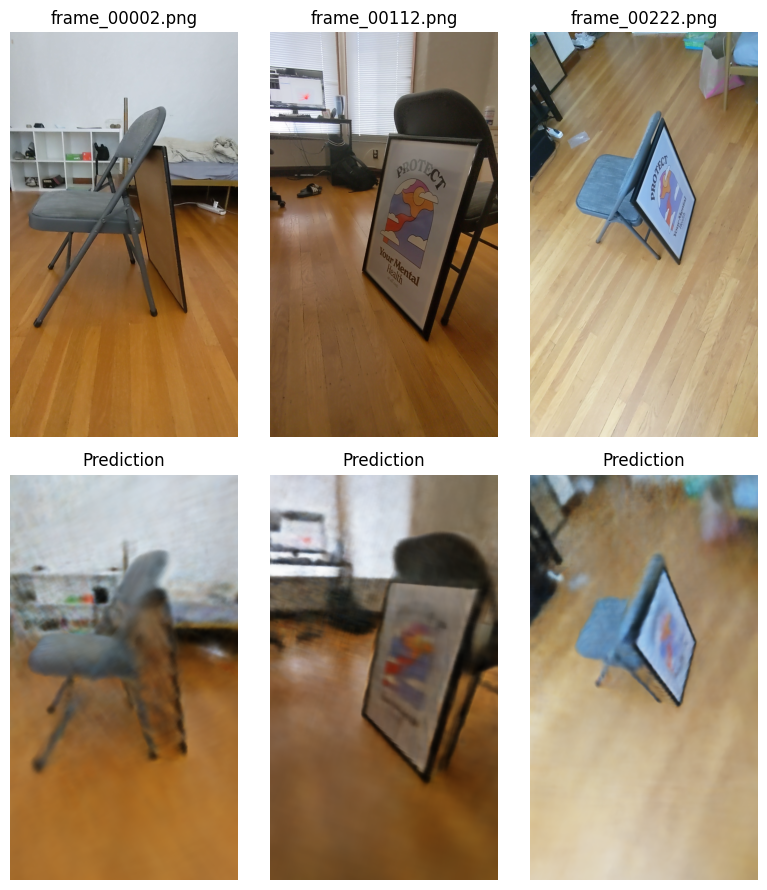

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(8, 9))    



for column, position in enumerate([0, 11, 22]):   
    axes[0, column].imshow(targets[position])  
    axes[0, column].set_title(test_names[position])  
  
  
    axes[1, column].imshow(predictions[position])   
    axes[1, column].set_title("Prediction")  

    axes[0, column].axis("off")  
    axes[1, column].axis("off")  

   
   
plt.tight_layout()  
plt.savefig(output_dir / "comparison.png", dpi=150)  
plt.show()   